# Amazon Laptop Scraper

### IMPORT REQUIRED LIBRARIES

In [1]:
# required lib 

#!pip install beautifulsoup4 requests pandas numpy
import requests
from bs4 import BeautifulSoup
import pandas as pd
import numpy as np
import time
import re

In [2]:
# install beautifulsoup4 and requests
#!pip install beautifulsoup4 requests

In [3]:
# take the url of the product page
URL ="https://www.amazon.in/s?k=laptops&crid=36D68A7C7ZL08&sprefix=laptops%2Caps%2C278&ref=nb_sb_noss_1"

In [4]:
# make header to avoid being blocked by amazon

headers = {
    'User-Agent':"Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/150.0.0.0 Safari/537.36"
}

In [5]:
# check the status of the request
response = requests.get(URL, headers=headers)

print(response.status_code)

200


In [6]:
# check the content 
print(response.content)

b'<!doctype html><html lang="en-in" class="a-no-js" data-19ax5a9jf="dingo"><!-- sp:feature:head-start -->\n<head><script>var aPageStart = (new Date()).getTime();</script><meta charset="utf-8"/>\n<!-- sp:end-feature:head-start -->\n<!-- sp:feature:csm:head-open-part1 -->\n\n<script type=\'text/javascript\'>var ue_t0=ue_t0||+new Date();</script>\n<!-- sp:end-feature:csm:head-open-part1 -->\n<!-- sp:feature:cs-optimization -->\n<meta http-equiv=\'x-dns-prefetch-control\' content=\'on\'>\n<link rel="preconnect" href="https://images-eu.ssl-images-amazon.com" crossorigin>\n<link rel="preconnect" href="https://m.media-amazon.com" crossorigin>\n<!-- sp:end-feature:cs-optimization -->\n<!-- sp:feature:csm:head-open-part2 -->\n<script type=\'text/javascript\'>\nwindow.ue_ihb = (window.ue_ihb || window.ueinit || 0) + 1;\nif (window.ue_ihb === 1) {\n\nvar ue_csm = window,\n    ue_hob = +new Date();\n(function(d){var e=d.ue=d.ue||{},f=Date.now||function(){return+new Date};e.d=function(b){return f()

In [7]:
# convert the content to beautifulsoup object
soup = BeautifulSoup(response.content, 'html.parser')

# print the soup content
print(soup.prettify())

<!DOCTYPE html>
<html class="a-no-js" data-19ax5a9jf="dingo" lang="en-in">
 <!-- sp:feature:head-start -->
 <head>
  <script>
   var aPageStart = (new Date()).getTime();
  </script>
  <meta charset="utf-8"/>
  <!-- sp:end-feature:head-start -->
  <!-- sp:feature:csm:head-open-part1 -->
  <script type="text/javascript">
   var ue_t0=ue_t0||+new Date();
  </script>
  <!-- sp:end-feature:csm:head-open-part1 -->
  <!-- sp:feature:cs-optimization -->
  <meta content="on" http-equiv="x-dns-prefetch-control"/>
  <link crossorigin="" href="https://images-eu.ssl-images-amazon.com" rel="preconnect"/>
  <link crossorigin="" href="https://m.media-amazon.com" rel="preconnect"/>
  <!-- sp:end-feature:cs-optimization -->
  <!-- sp:feature:csm:head-open-part2 -->
  <script type="text/javascript">
   window.ue_ihb = (window.ue_ihb || window.ueinit || 0) + 1;
if (window.ue_ihb === 1) {

var ue_csm = window,
    ue_hob = +new Date();
(function(d){var e=d.ue=d.ue||{},f=Date.now||function(){return+new Date

In [8]:
# make the empty list to store the data
data = []
print("Data list created")

Data list created


In [9]:
data = []
seen_titles = set()

for page in range(1, 200):

    # make the parameter for the request
    params = {
        'k': 'laptops',
        'page': page
    }

    # get the response from the request
    response = requests.get(URL, headers=headers, params=params, timeout=15)
    response.raise_for_status()

    # convert the content to beautifulsoup object
    soup = BeautifulSoup(response.content, 'html.parser')

    # find all Amazon product result cards
    product_cards = soup.select('div[data-component-type="s-search-result"]')

    # make the for loop to get the data from the product cards
    for product in product_cards:

        # step 1: extract the title
        title_tag = product.select_one('h2 span')
        if not title_tag:
            continue

        title = title_tag.get_text(" ", strip=True)
        title = ' '.join(title.split())

        # Skip irrelevant text and page headings
        lower_title = title.lower()
        if not title or len(title) < 10:
            continue
        if 'results for' in lower_title:
            continue
        if any(skip in lower_title for skip in [
            'trending now', 'best sellers', 'new releases', 'shop by', 'related searches'
        ]):
            continue
        if title in seen_titles:
            continue

        seen_titles.add(title)
    

        # Step 2: extract the price
        price_tag = product.select_one('span.a-price-whole')
        if price_tag:
            price = price_tag.get_text(" ", strip=True)
        else:
            price = None

        # Step 3 : Extract the brand
        match = re.search(r"^([A-Za-z]+)", title)
        brand = match.group(1) if match else None

        # Step 4: Extract the Ram 
        match = re.search(r"(\d+GB|RAM\s*(\d+GB)?|DDR\d?\s*(\d+GB)?|LPDDR\d?\s*(\d+GB)?)", title, re.IGNORECASE)
        ram = match.group(1) if match else None
        
        # Step 5: Extract the storage
        match = re.search(r"(\d+)\s*(GB|TB)\s*(?:SSD|Storage|HDD)", title, re.IGNORECASE)
        ssd_storage = f"{match.group(1)}{match.group(2)}" if match else "N/A"
#Step 6 : Extract the Color from the title using regex
        match = re.search(r"\b(Black|White|Silver|Gray|Grey|Red|Blue|Green|Yellow|Pink|Purple|Gold|Bronze|Rose Gold|Indigo|Glacier)\b", title, re.IGNORECASE)
        color = match.group(1) if match else "N/A"
        
        # Step 7: Extract the processor (Intel, AMD, Apple M/A chip, Snapdragon, MediaTek, etc)
        processor = "N/A"
        # Try to match Apple M series (M1, M2, M3, M4, M5, etc.)
        match = re.search(r"Apple\s+M(\d+)", title, re.IGNORECASE)
        if match:
            processor = f"Apple M{match.group(1)}"
        else:
            # Try to match Apple A series (A18, A17, A16, etc.)
            match = re.search(r"Apple\s+A(\d+)", title, re.IGNORECASE)
            if match:
                processor = f"Apple A{match.group(1)}"
            else:
                # Try other processor keywords
                processor_keywords = ["Intel", "AMD", "Snapdragon", "MediaTek", "Celeron"]
                for keyword in processor_keywords:
                    if re.search(rf"\b{keyword}\b", title, re.IGNORECASE):
                        processor = keyword
                        break
       # Step 8: Extract the OS from the title using regex
        os = "N/A"
        # Check for MacBook/macOS first (Apple specific)
        if re.search(r"\b(MacBook|macOS|Mac OS)\b", title, re.IGNORECASE):
            os = "MacOS"
        # Check for Apple processors (M or A series means MacOS)
        elif re.search(r"\bApple\s+[MA]\d+\b", title, re.IGNORECASE):
            os = "MacOS"
        # Check for Windows variations
        elif re.search(r"\b(Windows|Win\s*11|Win11|Win\s*10|Win10)\b", title, re.IGNORECASE):
            os = "Windows"
        # Check for other OS keywords
        else:
            OS_keywords = ["Linux", "Chrome OS", "Android", "iOS"]
            for keyword in OS_keywords:
                if re.search(rf"\b{keyword}\b", title, re.IGNORECASE):
                    os = keyword
                    break
        # Step 9: Extract the Rating from the container
        rating = "N/A"
        # Try multiple methods to find rating
        # Method 1: Look for i-star span
        rating_span = product.find("span", class_=lambda x: x and "i-star" in str(x).lower() if x else False)
        
        # Method 2: Look for aria-label attribute with rating
        if not rating_span:
            rating_span = product.find("span", {"aria-label": lambda x: x and "out of 5" in str(x).lower() if x else False})
        
        # Method 3: Look for a-icon-star class
        if not rating_span:
            rating_span = product.find("i", class_=lambda x: x and "a-icon-star" in str(x).lower() if x else False)
        
        if rating_span:
            # Try to get rating from aria-label
            aria_label = rating_span.get("aria-label")
            if aria_label:
                match = re.search(r"(\d+\.?\d*)\s*out of 5", aria_label)
                if match:
                    rating = match.group(1)
            else:
                # Try to get from text
                rating_text = rating_span.text.strip() if rating_span else ""
                match = re.search(r"(\d+\.?\d*)", rating_text)
                if match:
                    rating = match.group(1)

        # append the data to the list
        data.append({
            'title': title,
            'price': price,
            'brand': brand,
            'ram': ram,
            'storage': ssd_storage,
            'color': color,
            'processor': processor,
            'os':os,
            'rating':rating
        })


In [10]:
for product in data:
    print(f"Title: {product['title']}")
    print(f"Price: {product['price']}")
    print(f"Brand: {product['brand']}")
    print(f"Ram: {product['ram']}")
    print(f"Storage: {product['storage']}")
    print(f"Color: {product['color']}")
    print(f"Processor: {product['processor']}")
    print(f"os:{product['os']}")
    print(f"rating:{product["rating"]}")
    print("-" * 40)


Title: Lenovo ThinkBook 16 AMD Ryzen 5 7535HS (8GB RAM/512GB SSD/Win 11 Home/Office 2024/Backlit Keyboard/Fingerprint) 16" WUXGA IPS 300 Nits Thin & Light Laptop/1Y Warranty/Aluminium Top/1.7kg, 21MWA0BRIN
Price: 65,063
Brand: Lenovo
Ram: 8GB
Storage: 512GB
Color: N/A
Processor: AMD
os:Windows
rating:4.2
----------------------------------------
Title: Lenovo V14 Intel Core i3 13th Gen 14" FHD (1920x1080) Antiglare 250 Nits Thin and Light Laptop (16GB RAM/512GB SSD/Windows 11 Home/Office Home 2024/Iron Grey/1.43 kg), 83A0A0PCIN
Price: 70,990
Brand: Lenovo
Ram: 16GB
Storage: 512GB
Color: Grey
Processor: Intel
os:Windows
rating:3.6
----------------------------------------
Title: HP 15, AMD Ryzen 5 7520U,(16GB LPDDR5, 512GB SSD), Anti-Glare, Micro-Edge, FHD, 15.6''/39.6cm, Win 11, Office 24,M365 Basic(1yr)*,Silver, 1.59kg, fc0690au, FHD Camera, Backlit KB Laptop
Price: 59,950
Brand: HP
Ram: 16GB
Storage: 512GB
Color: Silver
Processor: AMD
os:Windows
rating:3.9
-----------------------------

In [11]:
# length of the data list
print(f"Number of products scraped: {len(data)}")

Number of products scraped: 278


In [12]:
# convert the data to a pandas  data frame
df = pd.DataFrame(data)
df.to_csv("amazon_laptop.csv",index=False)


In [13]:
df.head()

,title,price,brand,ram,storage,color,processor,os,rating
0,Lenovo ThinkBook 16 AMD Ryzen 5 7535HS (8GB RA...,"65,063",Lenovo,8GB,512GB,N/A,AMD,Windows,4.2
1,"Lenovo V14 Intel Core i3 13th Gen 14"" FHD (192...","70,990",Lenovo,16GB,512GB,Grey,Intel,Windows,3.6
2,"HP 15, AMD Ryzen 5 7520U,(16GB LPDDR5, 512GB S...","59,950",HP,16GB,512GB,Silver,AMD,Windows,3.9
3,"HP 15 Smartchoice, 13th Gen Intel Core i3-1315...","51,990",HP,8GB,512GB,Silver,Intel,Windows,4.1
4,"ASUS Vivobook 15, Smartchoice,Intel Core i3 13...","48,990",ASUS,12GB,512GB,Blue,Intel,Windows,4.2


In [14]:
# Data processing and Cleaning
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 278 entries, 0 to 277
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   title      278 non-null    object
 1   price      273 non-null    object
 2   brand      272 non-null    object
 3   ram        239 non-null    object
 4   storage    278 non-null    object
 5   color      278 non-null    object
 6   processor  278 non-null    object
 7   os         278 non-null    object
 8   rating     278 non-null    object
dtypes: object(9)
memory usage: 19.7+ KB


In [15]:
# cheack the shape of the dataframe
df.shape

(278, 9)

In [16]:
# drop the title column 
df=df.drop(columns=['title'])


In [17]:
# print the price columns 
print(df["price"])

0        65,063
1        70,990
2        59,950
3        51,990
4        48,990
         ...   
273      74,729
274      64,990
275    1,49,990
276      78,990
277      79,990
Name: price, Length: 278, dtype: object


In [18]:
# clean the price column by removing commas
df["price"]=df["price"].str.replace(',','')
df["price"]

0       65063
1       70990
2       59950
3       51990
4       48990
        ...  
273     74729
274     64990
275    149990
276     78990
277     79990
Name: price, Length: 278, dtype: object

In [20]:
# convert the price column to numeric type
df["price"]=pd.to_numeric(df["price"],errors='coerce')# Use errors="coerce" to handle the null vlaue

In [21]:
#  convert the float type to int64
df["price"] = df["price"].fillna(df["price"].mean())
df["price"] = df["price"].astype("int64")


In [22]:
# convert the price column to numeric type
df["price"]=pd.to_numeric(df["price"],errors='coerce')# Use errors="coerce" to handle the null vlaue

In [23]:
#  convert the float type to int64
df["price"] = df["price"].fillna(df["price"].mean())
df["price"] = df["price"].astype("int64")


In [24]:
# clean the ram column
df["ram"].value_counts()


ram
16GB      110
8GB        65
32GB       15
4GB        10
24GB        9
6GB         8
DDR5        7
RAM         7
12GB        5
LPDDR4      1
64GB        1
DDR7        1
Name: count, dtype: int64

In [25]:
# replace the string eg: RAM ,DDRS,LPDDRS,DDR7,DDR5,8gb with "unknwon"
df["ram"]= df["ram"].str.replace("RAM|DDR5|LPDDR4|DDR7|DDR4","unknown",regex=True)

# replace Gb
df["ram"]=df["ram"].str.replace("GB|gb","",regex=True)

# convert the ram column to the numreorc
df["ram"]=pd.to_numeric(df["ram"],errors="coerce")

In [26]:
# clean the ram column
df["ram"].value_counts()


ram
16.0    110
8.0      65
32.0     15
4.0      10
24.0      9
6.0       8
12.0      5
64.0      1
Name: count, dtype: int64

In [27]:
# covert the RAM into Integer
df['ram'] = df['ram'].astype('Int64')
df['ram']

0       8
1      16
2      16
3       8
4      12
       ..
273    16
274    16
275    16
276    16
277    16
Name: ram, Length: 278, dtype: Int64

In [28]:
df["storage"]

0      512GB
1      512GB
2      512GB
3      512GB
4      512GB
       ...  
273    512GB
274    512GB
275      1TB
276    512GB
277    512GB
Name: storage, Length: 278, dtype: object

In [29]:
# Convert to string first
df["storage"] = df["storage"].astype(str)

# Replace TB with GB
df["storage"] = df["storage"].str.replace("1TB", "1024GB", regex=False)
df["storage"] = df["storage"].str.replace("2TB", "2048GB", regex=False)

# Remove GB
df["storage"] = df["storage"].str.replace("GB", "", regex=False)

# Convert to integer
df["storage"] = pd.to_numeric(df["storage"], errors="coerce").astype("Int64")

In [30]:
# find the percentage of missing values in each column
missing_percentage = (df.isnull().sum() / len(df)) * 100
print(round(missing_percentage, 2))

price         0.00
brand         2.16
ram          19.78
storage       9.71
color         0.00
processor     0.00
os            0.00
rating        0.00
dtype: float64


In [ ]:
# Rating ddata types chnage to the numeric
df["Rating"] = pd.to_numeric(df["Rating"], errors="coerce")


In [ ]:
print(df["Rating"].dtype)
print(df["Rating"].head(10))

In [ ]:
# removing the special chrecters in the Rating
df["Rating"] = (
    df["Rating"]
    .astype(str)
    .str.extract(r'(\d+\.?\d*)')[0]
)

df["Rating"] = pd.to_numeric(df["Rating"], errors="coerce")


In [ ]:
# check the categorical columns and their unique values
categorical_columns = df.select_dtypes(include=['object']).columns

for column in categorical_columns:
    unique_values = df[column].unique()
    print(f"Column: {column}")
    print(f"Unique Values: {unique_values}")

In [ ]:
# statistical summary of the numerical columns

df.describe()

In [38]:
print(df[['price', 'ram', 'storage', 'rating']].dtypes)

price       int64
ram         Int64
storage     Int64
rating     object
dtype: object


In [39]:
print(df['price'].head(10))
print(df['ram'].head(10))
print(df['storage'].head(10))
print(df['rating'].head(10))

0     65063
1     70990
2     59950
3     51990
4     48990
5     52890
6     38690
7     44999
8    111990
9     81990
Name: price, dtype: int64
0     8
1    16
2    16
3     8
4    12
5    16
6     8
7     8
8    16
9    16
Name: ram, dtype: Int64
0     512
1     512
2     512
3     512
4     512
5     512
6    <NA>
7     512
8     512
9     512
Name: storage, dtype: Int64
0    4.2
1    3.6
2    3.9
3    4.1
4    4.2
5    4.0
6    5.0
7    4.0
8    N/A
9    4.1
Name: rating, dtype: object


In [40]:
print(df['rating'].head(20))
print(df['rating'].unique())

0     4.2
1     3.6
2     3.9
3     4.1
4     4.2
5     4.0
6     5.0
7     4.0
8     N/A
9     4.1
10    4.1
11    3.7
12    5.0
13    3.8
14    3.9
15    2.9
16    3.6
17    4.2
18    3.8
19    2.8
Name: rating, dtype: object
['4.2' '3.6' '3.9' '4.1' '4.0' '5.0' 'N/A' '3.7' '3.8' '2.9' '2.8' '4.8'
 '3.0' '4.3' '4.4' '3.2' '1.0' '2.7' '3.5' '4.6' '3.4' '4.5' '3.1' '1.5'
 '2.4' '1.6' '3.3' '4.9' '2.1' '2.0' '2.6']


In [41]:
import pandas as pd

df['rating'] = pd.to_numeric(df['rating'], errors='coerce')

In [42]:
print(df['rating'].dtype)

float64


In [43]:
df['rating'] = (
    df['rating']
      .astype(str)
      .str.replace('★', '', regex=False)
      .str.strip()
)

df['rating'] = pd.to_numeric(df['rating'], errors='coerce')

In [44]:
print(df.loc[pd.to_numeric(df['rating'], errors='coerce').isna(), 'rating'].unique())

[nan]


In [45]:
df['rating'].dropna()

0      4.2
1      3.6
2      3.9
3      4.1
4      4.2
      ... 
268    2.0
271    4.1
274    2.6
276    4.0
277    4.2
Name: rating, Length: 239, dtype: float64

In [46]:
df['ram'] = df['ram'].astype(float)
df['storage'] = df['storage'].astype(float)
df['rating'] = pd.to_numeric(df['rating'], errors='coerce')

# Box Plot Analysis of Smartphone Features
 

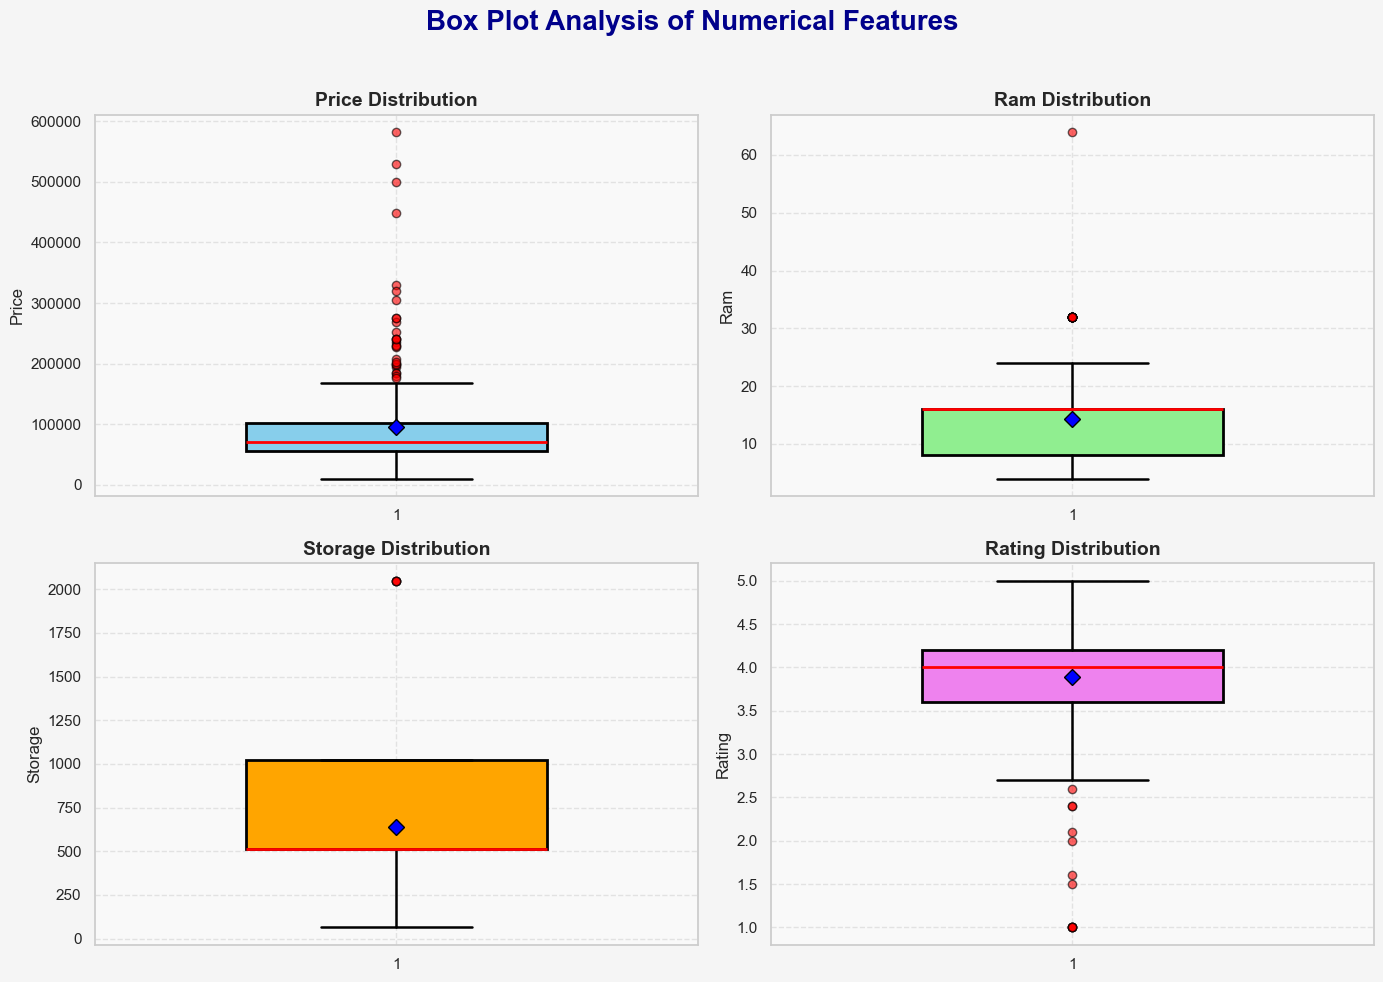

In [47]:
import matplotlib.pyplot as plt

# Create figure and subplots
fig, axes = plt.subplots(2, 2, figsize=(14, 10), facecolor='whitesmoke')

# Main Title
fig.suptitle(
    "Box Plot Analysis of Numerical Features",
    fontsize=20,
    fontweight='bold',
    color='darkblue'
)

# Columns and Colors
columns = ['price', 'ram', 'storage', 'rating']
colors = ['skyblue', 'lightgreen', 'orange', 'violet']

# Flatten axes for easy looping
axes = axes.ravel()

# Draw Boxplots
for ax, col, color in zip(axes, columns, colors):

    ax.boxplot(
        df[col].dropna(),
        patch_artist=True,
        showmeans=True,
        widths=0.5,
        boxprops=dict(facecolor=color, edgecolor='black', linewidth=2),
        medianprops=dict(color='red', linewidth=2),
        whiskerprops=dict(color='black', linewidth=1.8),
        capprops=dict(color='black', linewidth=1.8),
        meanprops=dict(marker='D',
                       markerfacecolor='blue',
                       markeredgecolor='black',
                       markersize=8),
        flierprops=dict(marker='o',
                        markerfacecolor='red',
                        markeredgecolor='black',
                        markersize=6,
                        alpha=0.6)
    )

    ax.set_title(f"{col.capitalize()} Distribution",
                 fontsize=14,
                 fontweight='bold')

    ax.set_ylabel(col.capitalize(), fontsize=12)
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.set_facecolor('#F9F9F9')

# Adjust layout
plt.tight_layout(rect=[0, 0, 1, 0.96])

plt.show()

# By UsingSeaborn provides cleaner default styling with less code:

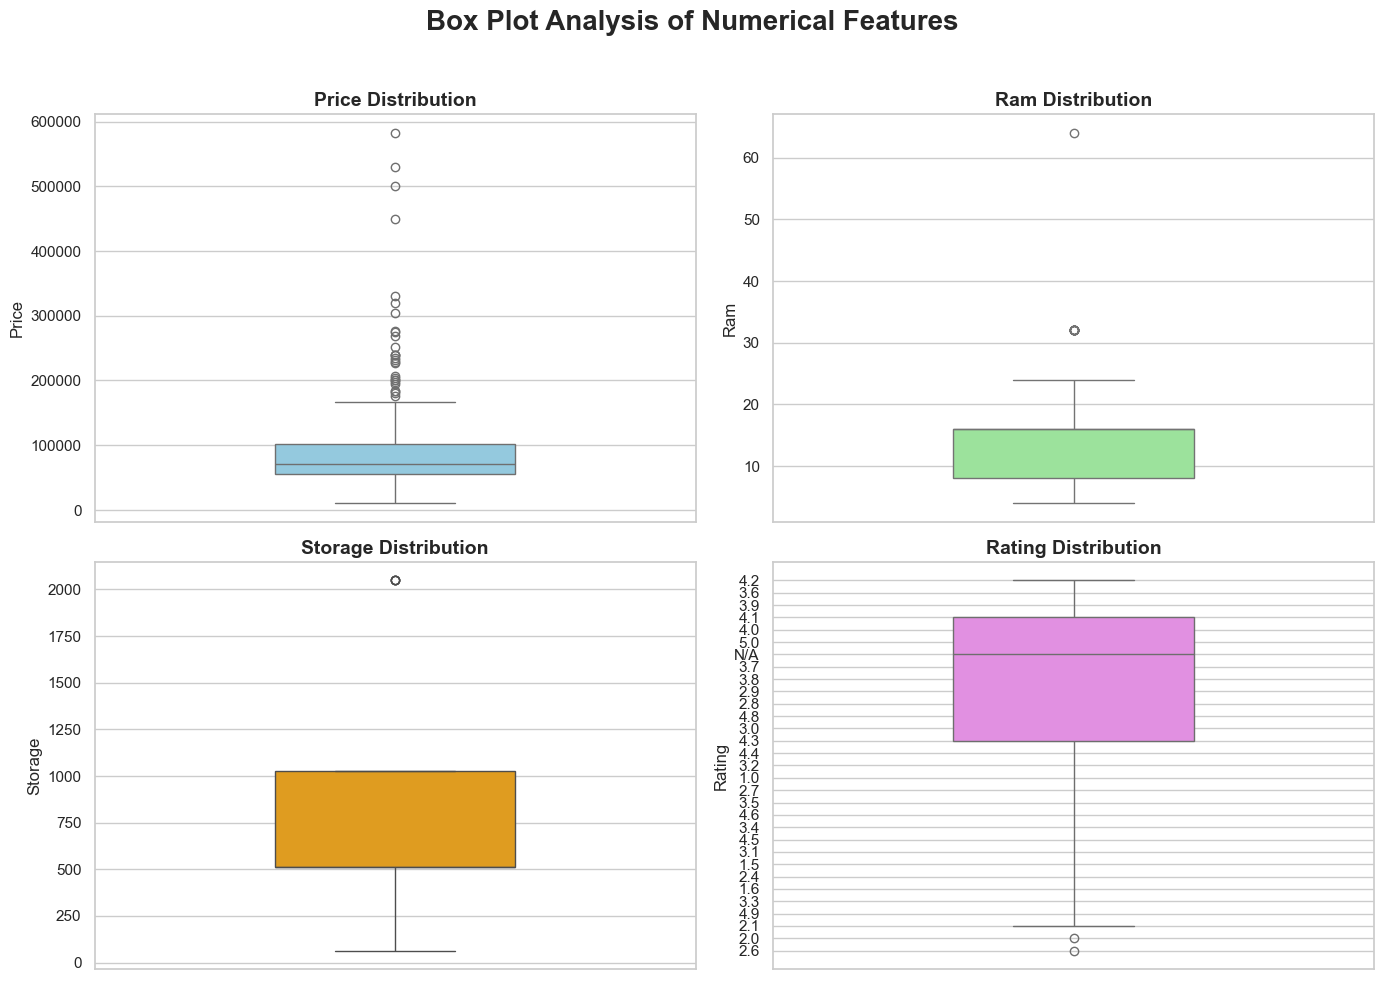

In [37]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

columns = ['price', 'ram', 'storage', 'rating']
colors = ['skyblue', 'lightgreen', 'orange', 'violet']

for ax, col, color in zip(axes.flatten(), columns, colors):
    sns.boxplot(
        y=df[col],
        color=color,
        width=0.4,
        ax=ax
    )

    ax.set_title(f"{col.capitalize()} Distribution",
                 fontsize=14,
                 fontweight='bold')
    ax.set_xlabel("")
    ax.set_ylabel(col.capitalize())

fig.suptitle("Box Plot Analysis of Numerical Features",
             fontsize=20,
             fontweight='bold')

plt.tight_layout(rect=[0,0,1,0.96])
plt.show()

# ================
#   THANK YOU
# =================